# Week 6 In-Class Assessment

## Time Series Filtering/Smoothing

In this notebook, we're going to start exploring what it means to filter or smooth data. We're going to start by using techniques that we are already familiar with, namely linear regression. 

Let's start by taking a look at the NASA GISS GISTEMP data product: https://data.giss.nasa.gov/gistemp/

In [1]:
#  Import packages
import numpy as np
from matplotlib import pyplot as plt
import scipy.stats as stats
import matplotlib as mpl
mpl.rc('font',size=16) #set default font size and weight for plots

In [2]:
#  Read in the GISTEMP Data. 
#  Column 0 is the year, Columns 1-12 are months Jan. - Dec. and Column 13 is the Annual mean
filename = "GLBTs.csv"
GISTEMP = np.genfromtxt(filename,delimiter=",")

In [3]:
years = GISTEMP[:,0]
#print(years)

In [4]:
#  Globally and annually-averaged temperature anomaly (the 1951-1980 climatology has been subtracted)
Ts = GISTEMP[:,13]
#print(Ts)

Text(0.5, 0, 'Year')

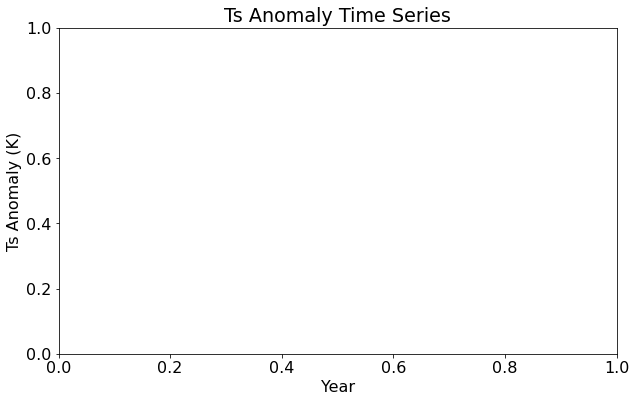

In [5]:
#  Plot this time series with years on the x-axis and the temperature anomaly on the y-axis
plt.figure(figsize=(10,6))
#plt.plot()
plt.title("Ts Anomaly Time Series")
plt.ylabel("Ts Anomaly (K)")
plt.xlabel("Year")

Time series filtering or smoothing are ways that we can separate high frequencies and low frequencies from our data. 

For example, in the case of our temperature anomaly time series, we have a very low-frequency, long-term trend and higher-frequency, year-to-year variability superimposed on top.

So, let's filter the data by fitting a linear trend to the data to represent the lowest frequency in our data and then removing this component.

In [19]:
#smoothed temperature anomaly timeseries, i.e., the linear trend
Ts_hat = 

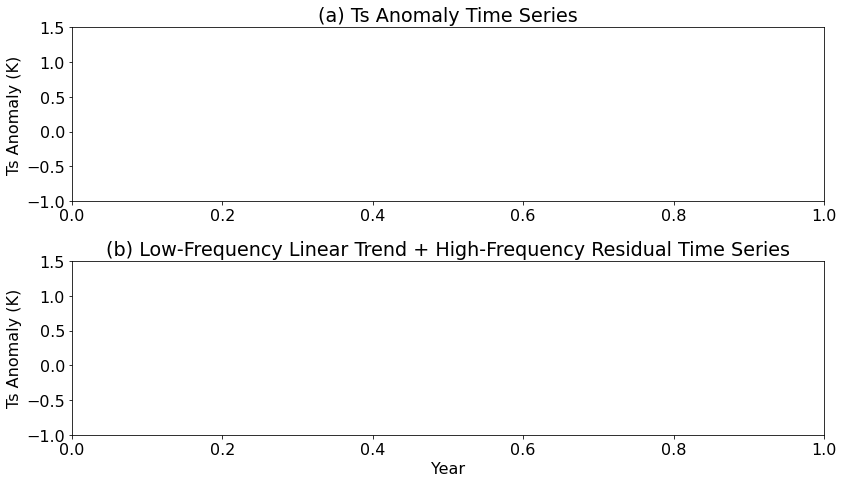

In [8]:
#Plot this time series with years on the x-axis and the temperature anomaly on the y-axis
plt.figure(figsize=(12,7))
#Plot orignial temperature anomaly with the fitted linear trend
plt.subplot(2,1,1)
#plt.plot()
#plt.plot()
plt.title("(a) Ts Anomaly Time Series")
plt.ylabel("Ts Anomaly (K)")
plt.ylim(-1,1.5)
plt.tight_layout()

#Plot the linear trend and the residual, i.e. (Ts - Ts_hat) on the same plot
plt.subplot(2,1,2)
#plt.plot()
#plt.plot()
plt.ylim(-1,1.5)
plt.title("(b) Low-Frequency Linear Trend + High-Frequency Residual Time Series")
plt.xlabel("Year")
plt.ylabel("Ts Anomaly (K)")
plt.tight_layout()

We've seen this before. Removing the trend from the data is often called *detrending*, but it actually falls into a broader class of methods called **filtering**.

The trend itself is often considered the **smoothed** part of the time series because we are smoothing out the higher-frequencies when to fit a line.

Let's take it another step. Suppose rather than fitting a linear trend, we fit a quadratic to our surface temperature anomaly time series. We can do this using np.polyfit (recall that the third argument in the polyfit function refers to the order of the fit).

In [21]:
#smoothed temperature anomaly timeseries, i.e. the quadratic fit
Ts_hat2 = 

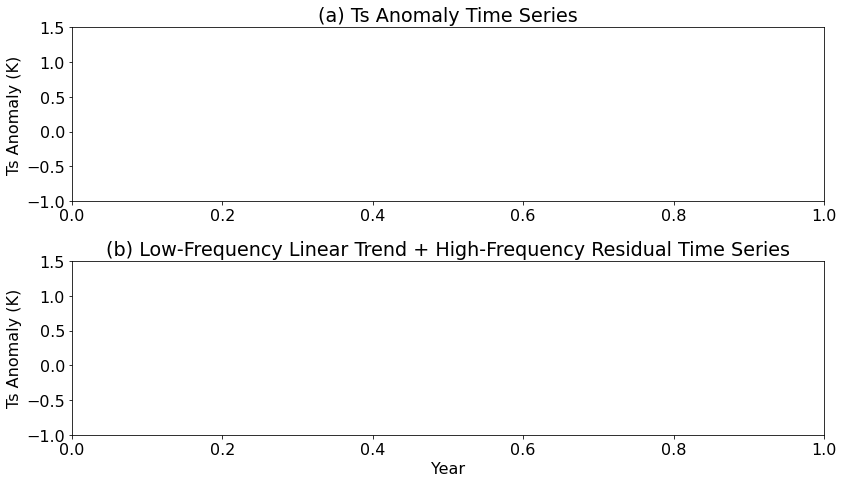

In [9]:
#Plot this time series with years on the x-axis and the temperature anomaly on the y-axis
plt.figure(figsize=(12,7))
#Plot orignial temperature anomaly with the fitted quadratic trend
plt.subplot(2,1,1)
#plt.plot()
#plt.plot()
plt.title("(a) Ts Anomaly Time Series")
plt.ylabel("Ts Anomaly (K)")
plt.ylim(-1,1.5)
plt.tight_layout()

#Plot the quadratic trend and the residual, i.e. (Ts - Ts_hat2) on the same plot
plt.subplot(2,1,2)
#plt.plot()
#plt.plot()
plt.ylim(-1,1.5)
plt.title("(b) Low-Frequency Linear Trend + High-Frequency Residual Time Series")
plt.xlabel("Year")
plt.ylabel("Ts Anomaly (K)")
plt.tight_layout()

Does it look like we get a better fit using a quadratic? Maybe. Neither is a perfect match.

Filtering is all about isolating the frequencies that have the most meaning with respect to the particular problem we are trying to address.

Sometimes we may want to remove the "noise" and isolate the low-frequencies, such as trends; other times we may want to remove the low-frequencies, such as the trend (as we are doing in Assignment 2), from our data to focus on other processes.

### Now, let's take a look at a different sort of data set. 

We are going to create a synthetic noisy sine wave with a trend.

In [10]:
#  Let's create a noisy sine wave with a trend
x = np.arange(-5*np.pi,5*np.pi,np.pi/100)

# initialize arrays
y = np.zeros((len(x)))
rand = np.zeros((len(x)))

# loop over x
for i in range(len(x)):
    rand[i] = 0.2*np.random.normal(0,1)
    y[i] = np.sin(x[i]) + rand[i] + 0.1*x[i] # note that we are adding three components together

Plot y as a function of x.

In [12]:
#  Plot the new data set we created:
plt.figure(figsize=(10,6))
#plt.plot()

<Figure size 720x432 with 0 Axes>

<Figure size 720x432 with 0 Axes>

Now, we see that there are actually two low-freqency signals that might be of interest: the trend and the sinusoidal oscillaion, perhaps something like a seasonal cycle (think Mauna Loa CO2 data) or ENSO.

Suppose we want to isolate one of these low-frequency components, or maybe the high-frequency component. With this synthetic data set, we can easily do this. Let's see what all these different frequencies look like on their own. 

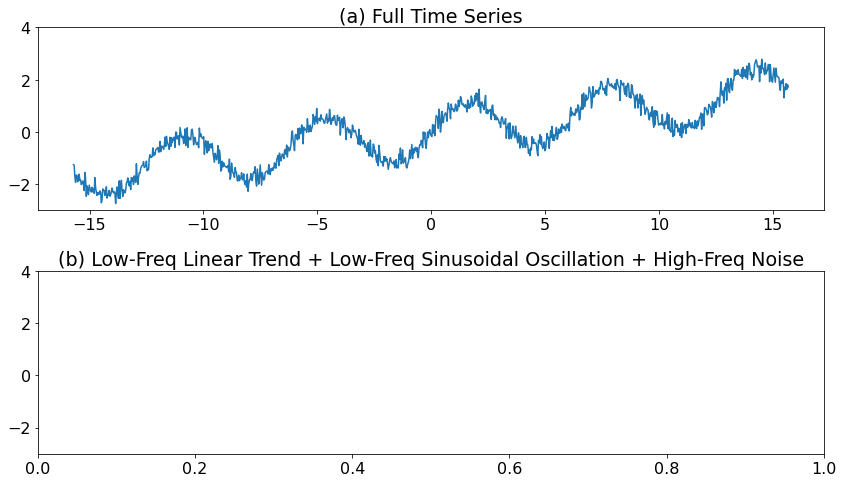

In [14]:
#  Plot this time series with years on the x-axis and the temperature anomaly on the y-axis
plt.figure(figsize=(12,7))

#  Plot y
plt.subplot(2,1,1)
plt.plot(x,y)
plt.title("(a) Full Time Series")
plt.ylim(-3,4)
plt.tight_layout()

#  Now, plot the three distinct components of y as a function of x
plt.subplot(2,1,2)
#plt.plot()
#plt.plot()
#plt.plot()
plt.ylim(-3,4)
plt.title("(b) Low-Freq Linear Trend + Low-Freq Sinusoidal Oscillation + High-Freq Noise")
plt.tight_layout()

We were able to separate these different frequencies because we created a synthetic data set to play around with - we  cheated!

Over the next few weeks, we will be learning methods to separate these frequencies without cheating! We will use the concept of Fourier Series.